#Music Popularity Data Project

Here is the Initial import of required libraries



In [ ]:
#Initial importing of libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


# Phase 1: Business Understanding







***Context and problem***


---



The goal of this project is to understand to what extent can a regression model predict a songs streaming popularity based on musical elements such as tempo, danceability, loudness,
instrumentalness, and genre.

**Stakeholders & Users**

---
This project will apply heavily to music artists or anyone interested in delving into music as a career as it should show what parts of music are more important in direct correlation to popularity



**Business or practical objective**

---
The business goals of this project are to:


*   Provide an understanding of what elements influence song popularity
*   Provide an understanding of what elements influence other elements in a song
*   Determine if any elements depend on others
*   Determine whatt elements (if any) are required for a successfull song

This will be done in order to help song artists and producers optimize track characteristics for audience engagement? Can this be done accurately and what elements influence the most? We will be using CRISP-DM process to determine this.


**Analytics objective**

---


The goal of this project is to understand to what extent can a regression model predict a songs streaming popularity based on musical elements such as tempo, danceability, loudness,
instrumentalness, and genre.


**Success criteria**


---

***Technical Criteria***

Provide an accurate correlation matrix describing which values directly correlate with eachother and how they affect the popularity of a song

***Practical Criteria***

Provide a legible understanding of how and what music features could help create a better and more popular song

**Constraints and assumptions**


---
The immediate scope constraint with this project is the fact myy chosen data set is from 2000 - 2019. Due to this data set being 7 years out of date, information predicted in this project will likely be inaccurate to nowadays music.

Also, as this list is the top hits from Spotify only, any music that is not present on Spotify will be ignored and therefore cannot provide all actual data

**Initial project plan**


---

This project will follow the CRISP-DM lifecycle, and will be formed under the following headings:

***Phase 1: Business Understanding***

***Phase 2: Business Understanding***

***Phase 3: Data Preparation***

***Phase 4: Modelling***

***Phase 5: Evaluation***

***Phase 6: Deployment and Recommendations***




# Phase 2: Data Understanding

In this section, we will begin to take a more in depth look at the data and what it actually means. First we need to understand what each row means in the data set, and determine if any rows are irrelevant to this project

**artist:** Name of the Artist.

**song:** Name of the Track.

**duration_ms:** Duration of the track in milliseconds.

**explicit:** The lyrics or content of a song or a music video contain one or more of the criteria which could be considered offensive or unsuitable for children.

**year:** Release Year of the track.

**popularity:** The higher the value the more popular the song is.

**danceability:** Danceability describes how suitable a track is for dancing based on a combination of musical elements including tempo, rhythm stability, beat strength, and overall regularity. A value of 0.0 is least danceable and 1.0 is most danceable.

**energy:** Energy is a measure from 0.0 to 1.0 and represents a perceptual measure of intensity and activity.

**key:** The key the track is in. Integers map to pitches using standard Pitch Class notation. E.g. 0 = C, 1 = C♯/D♭, 2 = D, and so on. If no key was detected, the value is -1.

**loudness:** The overall loudness of a track in decibels (dB). Loudness values are averaged across the entire track and are useful for comparing relative loudness of tracks. Loudness is the quality of a sound that is the primary psychological correlate of physical strength (amplitude). Values typically range between -60 and 0 db.

**mode:** Mode indicates the modality (major or minor) of a track, the type of scale from which its melodic content is derived. Major is represented by 1 and minor is 0.

**speechiness:** Speechiness detects the presence of spoken words in a track. The more exclusively speech-like the recording (e.g. talk show, audio book, poetry), the closer to 1.0 the attribute value. Values above 0.66 describe tracks that are probably made entirely of spoken words. Values between 0.33 and 0.66 describe tracks that may contain both music and speech, either in sections or layered, including such cases as rap music. Values below 0.33 most likely represent music and other non-speech-like tracks.

**acousticness:** A confidence measure from 0.0 to 1.0 of whether the track is acoustic. 1.0 represents high confidence the track is acoustic.
instrumentalness: Predicts whether a track contains no vocals. "Ooh" and "aah" sounds are treated as instrumental in this context. Rap or spoken word tracks are clearly "vocal". The closer the instrumentalness value is to 1.0, the greater likelihood the track contains no vocal content. Values above 0.5 are intended to represent instrumental tracks, but confidence is higher as the value approaches 1.0.

**liveness:** Detects the presence of an audience in the recording. Higher liveness values represent an increased probability that the track was performed live. A value above 0.8 provides strong likelihood that the track is live.
valence: A measure from 0.0 to 1.0 describing the musical positiveness conveyed by a track. Tracks with high valence sound more positive (e.g. happy, cheerful, euphoric), while tracks with low valence sound more negative (e.g. sad, depressed, angry).

**tempo:** The overall estimated tempo of a track in beats per minute (BPM). In
musical terminology, tempo is the speed or pace of a given piece and derives directly from the average beat duration.

**genre:** Genre of the track.

*This information was taken directly from the [description of the dataset itself on Kaggle](https://www.kaggle.com/datasets/paradisejoy/top-hits-spotify-from-20002019/data)*

In [4]:
#Here ive displayed the first 5 rows as an example
music_data = pd.read_csv('songs_normalize.csv');
music_data.head()

,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre
0,Britney Spears,Oops!...I Did It Again,211160,False,2000,77,0.751,0.834,1,-5.444,0,0.0437,0.3000,0.000018,0.3550,0.894,95.053,pop
1,blink-182,All The Small Things,167066,False,1999,79,0.434,0.897,0,-4.918,1,0.0488,0.0103,0.000000,0.6120,0.684,148.726,"rock, pop"
2,Faith Hill,Breathe,250546,False,1999,66,0.529,0.496,7,-9.007,1,0.0290,0.1730,0.000000,0.2510,0.278,136.859,"pop, country"
3,Bon Jovi,It's My Life,224493,False,2000,78,0.551,0.913,0,-4.063,0,0.0466,0.0263,0.000013,0.3470,0.544,119.992,"rock, metal"
4,*NSYNC,Bye Bye Bye,200560,False,2000,65,0.614,0.928,8,-4.806,0,0.0516,0.0408,0.001040,0.0845,0.879,172.656,pop


***Initial Data Collection Report***


---
The data set I will be using for this project is the [Top Hits Spotify from 2000-2019](https://www.kaggle.com/datasets/paradisejoy/top-hits-spotify-from-20002019?resource=download) The data was collected with the Spotify library for Python by Mark Koverha.

This dataset contains audio statistics of the top 2000 tracks on Spotify from 2000-2019. The data contains about 18 columns each describing the track and it's qualities.




***Data Description Report***


---



***Data Exploration Report***


---



***Data Quality Report***


---



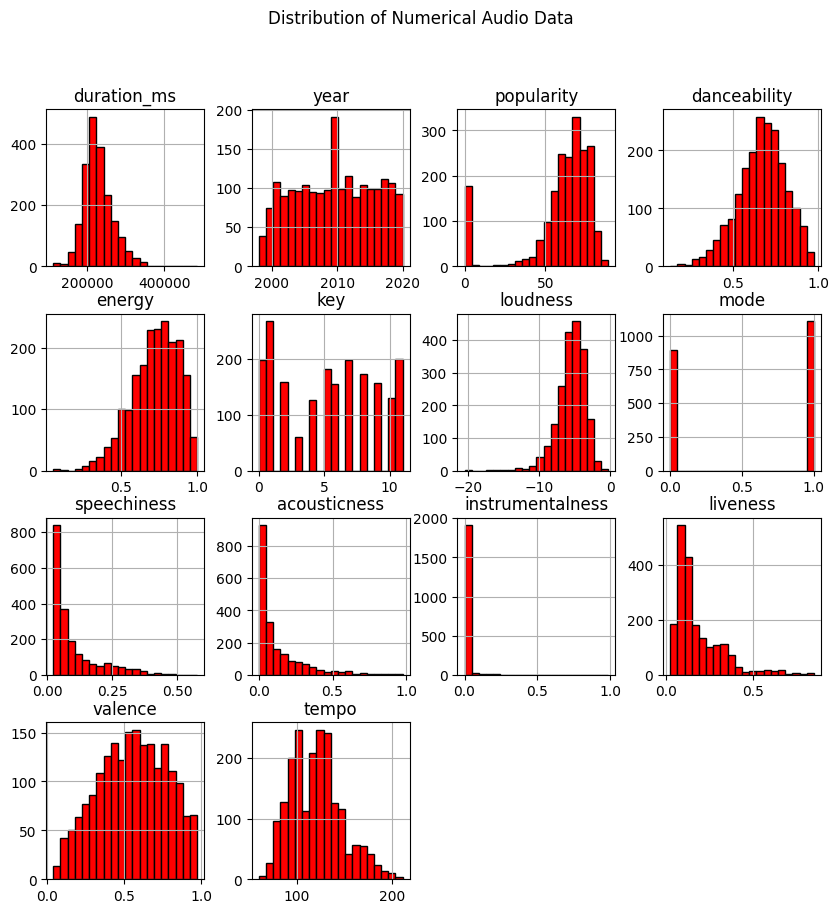

In [ ]:
#Histogram showing each distribution of each numerical piece of data
df.hist(bins=20, figsize=(10, 10), color='red', edgecolor='black')
plt.suptitle('Distribution of Numerical Audio Data')

plt.show()

I have also displayed a list of the top 20 genres below, as assumingly, genre will be playing a big role in a songs popularity. This count plot shows us that most songs in this data-set are mostly pop/hip hop. This is important to keep in mind later when we compare this data agaainst popularity

/tmp/ipykernel_550/1325316326.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


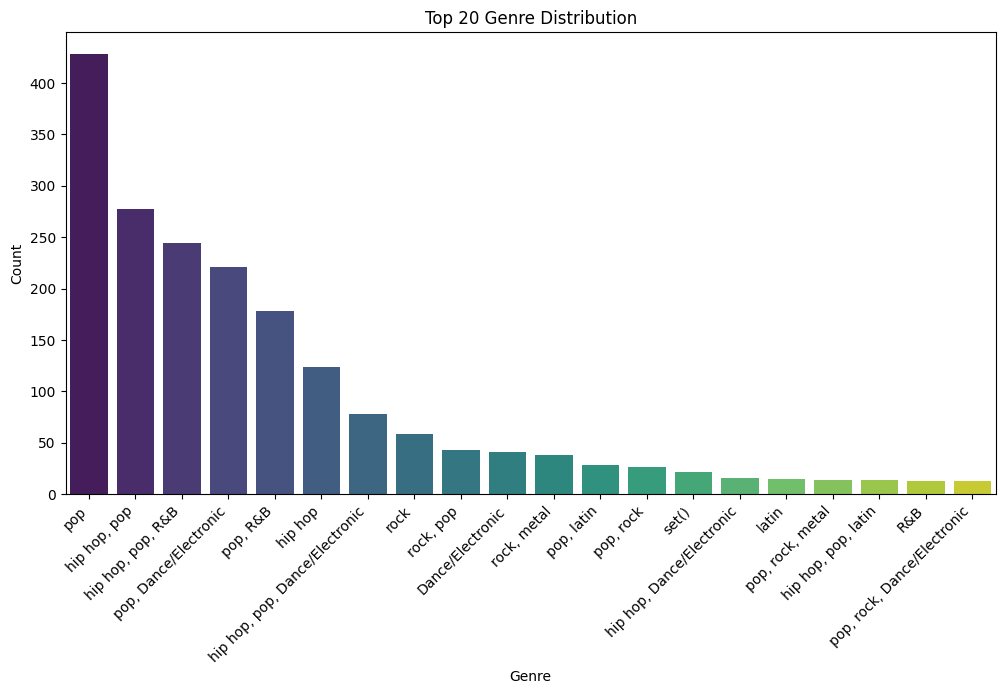

In [ ]:
#A conuntplot showing the distribution of music generes in the dataset
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='genre',
    palette='viridis',
    order=df['genre'].value_counts().index[:20]
)

plt.title('Top 20 Genre Distribution')
plt.xlabel('Genre')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')


plt.show()

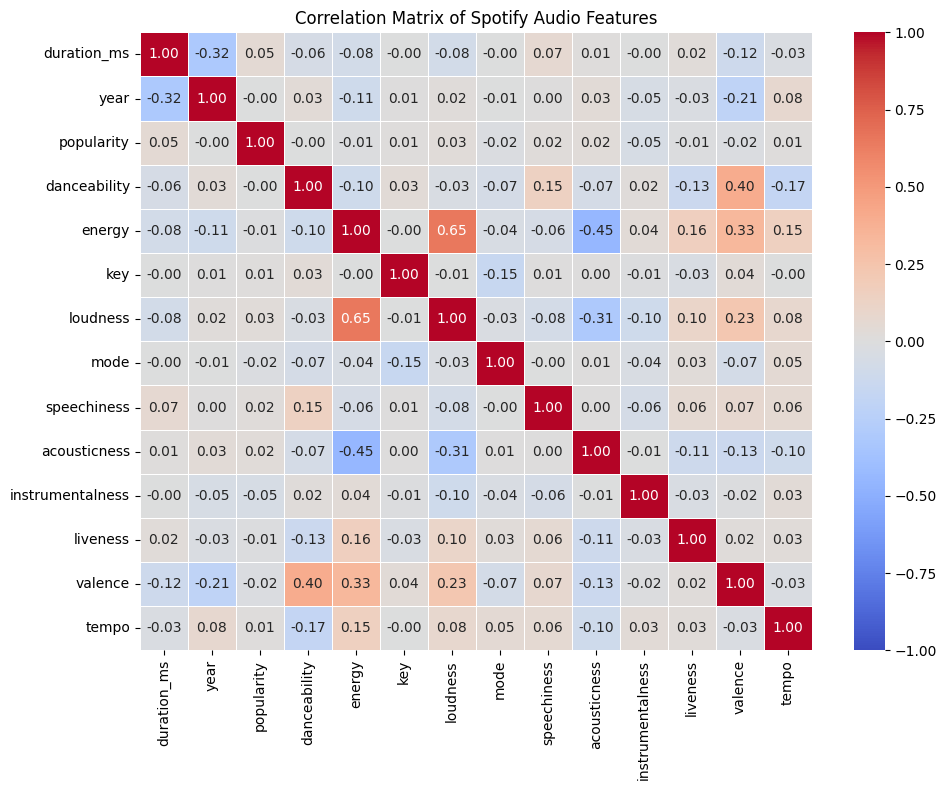